# LAB 09 — Bias, Variance and Imbalanced Data
# Student Information
## Name: Ritika Lund
## Student ID: 023-24-0262
## Section: H
## GitHub: https://github.com/Ritika-lund
## Kaggle : https://www.kaggle.com/ritikalund
## Dataset:Stroke Prediction Dataset (Kaggle)
## Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

# Part 0 : Setup and the Data 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve, StratifiedKFold
from sklearn.model_selection import learning_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,precision_score, recall_score, f1_score
)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

# Task 1
# imbalanced-learn installed

# Task 2

In [2]:
df=pd.read_csv("healthcare-dataset-stroke-data_1.csv")
print("Dataset shape :", df.shape)
print(df.head())
print("Columns name :")
print(df.columns.tolist())
print("Missing values :\n",df.isnull().sum())

print("\nGender counts:")
print(df["gender"].value_counts(dropna=False))

print("\nStroke counts:")
print(df["stroke"].value_counts(dropna=False))

print("\nStroke percentages:")
print(df["stroke"].value_counts(normalize=True, dropna=False) * 100)

Dataset shape : (5110, 12)
      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  
Columns name :
['id', 'gender

# Task 3

In [3]:
df=df.drop(columns=['id'])
print("Shape after removing ID:", df.shape)
df = df[df["gender"] != "Other"].copy()
print("Shape after removing rare gender category:", df.shape)
print("\nRemaining gender counts:")
print(df["gender"].value_counts())
df=pd.get_dummies(
     df,
    columns=df.select_dtypes(include="object").columns,
    dtype=int
)
print("Shape after encoding:", df.shape)
display(df.head())

Shape after removing ID: (5110, 11)
Shape after removing rare gender category: (5109, 11)

Remaining gender counts:
gender
Female    2994
Male      2115
Name: count, dtype: int64
Shape after encoding: (5109, 21)


D:\Temp\ipykernel_7068\624381954.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columns=df.select_dtypes(include="object").columns,


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,ever_married_No,ever_married_Yes,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,0,1,0,1,...,0,1,0,0,0,1,0,1,0,0
1,61.0,0,0,202.21,NaN,1,1,0,0,1,...,0,0,1,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,0,1,0,1,...,0,1,0,0,1,0,0,0,1,0
3,49.0,0,0,171.23,34.4,1,1,0,0,1,...,0,1,0,0,0,1,0,0,0,1
4,79.0,1,0,174.12,24.0,1,1,0,0,1,...,0,0,1,0,1,0,0,0,1,0


# Task 4

In [4]:
X = df.drop(columns=["stroke"])
y = df["stroke"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())
SEED=42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)


print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values in training:", int(X_train.isnull().sum().sum()))
print("Missing values in test:", int(X_test.isnull().sum().sum()))

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled training data:")
display(X_train_scaled.head())

print("\nScaled test data:")
display(X_test_scaled.head())

Features shape: (5109, 20)
Target shape: (5109,)

Target distribution:
stroke
0    4860
1     249
Name: count, dtype: int64
Training features: (4087, 20)
Test features: (1022, 20)

Training target distribution:
stroke
0    3888
1     199
Name: count, dtype: int64

Test target distribution:
stroke
0    972
1     50
Name: count, dtype: int64
Missing values in training: 0
Missing values in test: 0
Scaled training data:


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
845,0.209397,-0.323411,-0.245319,-0.821221,0.549234,0.839671,-0.839671,-0.717905,0.717905,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,-0.994875,0.994875,-0.658432,-0.460478,1.299544,-0.421272
3745,-0.629845,-0.323411,-0.245319,-0.485884,-0.988900,0.839671,-0.839671,1.392942,-1.392942,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,-0.994875,0.994875,-0.658432,-0.460478,1.299544,-0.421272
4184,-0.364822,-0.323411,-0.245319,0.302317,-0.769166,0.839671,-0.839671,-0.717905,0.717905,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,1.005152,-1.005152,-0.658432,-0.460478,1.299544,-0.421272
3410,-0.232310,-0.323411,-0.245319,0.062342,0.497532,-1.190942,1.190942,-0.717905,0.717905,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,1.005152,-1.005152,-0.658432,-0.460478,1.299544,-0.421272
284,-1.292405,-0.323411,-0.245319,-0.527297,0.355351,-1.190942,1.190942,1.392942,-1.392942,2.596253,-0.062692,-1.148132,-0.440434,-0.396402,-0.994875,0.994875,1.518761,-0.460478,-0.769500,-0.421272



Scaled test data:


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
3667,-0.674016,3.092042,-0.245319,-0.497748,0.975775,0.839671,-0.839671,-0.717905,0.717905,2.596253,-0.062692,-1.148132,-0.440434,-0.396402,1.005152,-1.005152,-0.658432,-0.460478,1.299544,-0.421272
2217,-1.778282,-0.323411,-0.245319,-0.281950,-1.208633,0.839671,-0.839671,1.392942,-1.392942,-0.385170,-0.062692,-1.148132,-0.440434,2.522690,-0.994875,0.994875,1.518761,-0.460478,-0.769500,-0.421272
374,0.430250,-0.323411,-0.245319,-0.928896,0.277798,0.839671,-0.839671,-0.717905,0.717905,2.596253,-0.062692,-1.148132,-0.440434,-0.396402,1.005152,-1.005152,-0.658432,-0.460478,-0.769500,2.373761
2392,-0.364822,-0.323411,-0.245319,-0.820997,1.803007,-1.190942,1.190942,-0.717905,0.717905,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,1.005152,-1.005152,-0.658432,-0.460478,1.299544,-0.421272
299,0.651103,-0.323411,-0.245319,-0.259564,0.032214,0.839671,-0.839671,-0.717905,0.717905,-0.385170,-0.062692,0.870980,-0.440434,-0.396402,1.005152,-1.005152,1.518761,-0.460478,-0.769500,-0.421272


# Task 5

In [5]:
print("\nStroke cases in training:", int(y_train.sum()))
print("Stroke cases in test:", int(y_test.sum()))


Stroke cases in training: 199
Stroke cases in test: 50


# Question
## a) In 2-3 lines: how imbalanced is the data? Why did we use stratify=y, and what could go wrong with only a few stroke cases in the test set? 
    The dataset is highly imbalanced, with approximately 4.9% of patients having a stroke and 95.1% not having a stroke. We used stratify=y to preserve the proportion of both classes in the training and test sets. If the test set contains too few stroke cases, the evaluation metrics, especially recall and precision, may become unreliable and may not represent the model's true performance.

# Part 1 : The Accuracy Trap

# Task 1 

In [6]:
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)


baseline_pred = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Accuracy (%):", round(baseline_accuracy * 100, 2))

Baseline Accuracy: 0.9511
Baseline Accuracy (%): 95.11


# Task 2

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
0,0.9521,1.0,0.02,0.0392,0.8393,0.2696


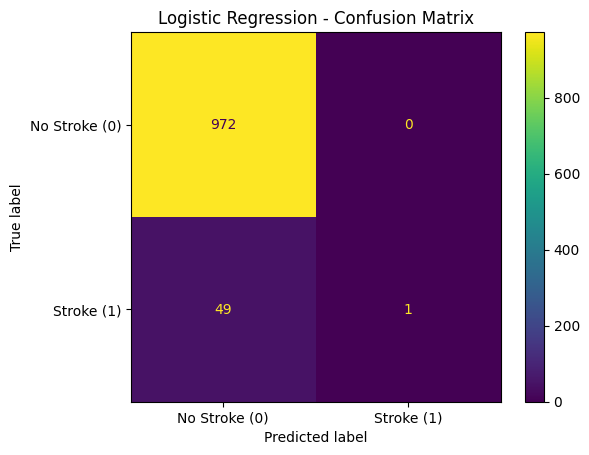

[[972   0]
 [ 49   1]]


In [7]:
lr = LogisticRegression(max_iter=1000, random_state=SEED)
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)
lr_prob = lr.predict_proba(X_test_scaled)[:, 1]
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

lr_results = {
    "Accuracy": accuracy_score(y_test, lr_pred),
    "Precision": precision_score(y_test, lr_pred, zero_division=0),
    "Recall": recall_score(y_test, lr_pred, zero_division=0),
    "F1": f1_score(y_test, lr_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, lr_prob),
    "PR AUC": average_precision_score(y_test, lr_prob)
}

display(pd.DataFrame([lr_results]).round(4))


cm = confusion_matrix(y_test, lr_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Stroke (0)", "Stroke (1)"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

print(cm)

# Task 3

In [8]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    }

# Question 
## a) Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?
    The baseline achieves 95.11% accuracy by predicting every patient as having no stroke. Logistic Regression achieves 95.21% accuracy, but detects only 1 of the 50 stroke patients. Therefore, accuracy is misleading for this imbalanced dataset. Recall, F1-score, PR AUC, and the confusion matrix provide a clearer picture of stroke detection performance.
## b)  Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?
    A false negative occurs when a patient who actually had a stroke is predicted as having no stroke. In a hospital, this could result in a patient being missed for further assessment. Recall is especially important because it measures the proportion of actual stroke cases detected. Precision, F1-score, and PR AUC should also be considered to evaluate false alarms and overall detection quality.

# Part 2 : Underfitting, Overfitting, Bias and Variance 


# Task 1

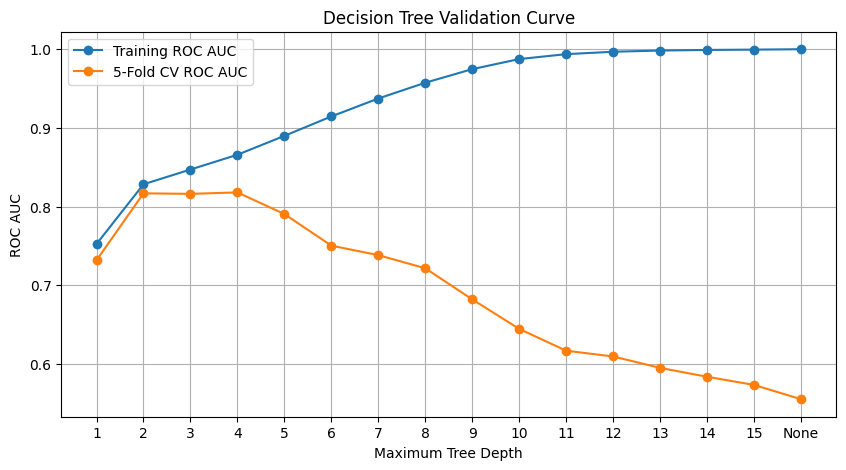

,Depth,Training ROC AUC,CV ROC AUC
0,1,0.7523,0.7317
1,2,0.8283,0.8168
2,3,0.8470,0.8161
3,4,0.8658,0.8180
4,5,0.8898,0.7904
5,6,0.9145,0.7503
6,7,0.9373,0.7382
7,8,0.9574,0.7215
8,9,0.9747,0.6819
9,10,0.9875,0.6444


Best depth: 4
Best mean CV ROC AUC: 0.818


In [9]:
depths = list(range(1, 16)) + [None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

train_scores, cv_scores = validation_curve(
    DecisionTreeClassifier(random_state=SEED),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=depths,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

depth_labels = [str(d) for d in depths]

plt.figure(figsize=(10, 5))
plt.plot(depth_labels, train_mean, marker="o", label="Training ROC AUC")
plt.plot(depth_labels, cv_mean, marker="o", label="5-Fold CV ROC AUC")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("ROC AUC")
plt.title("Decision Tree Validation Curve")
plt.legend()
plt.grid(True)
plt.show()

results_21 = pd.DataFrame({
    "Depth": depth_labels,
    "Training ROC AUC": train_mean,
    "CV ROC AUC": cv_mean
})

display(results_21.round(4))

best_index = np.argmax(cv_mean)
print("Best depth:", depth_labels[best_index])
print("Best mean CV ROC AUC:", round(cv_mean[best_index], 4))

# Task 2

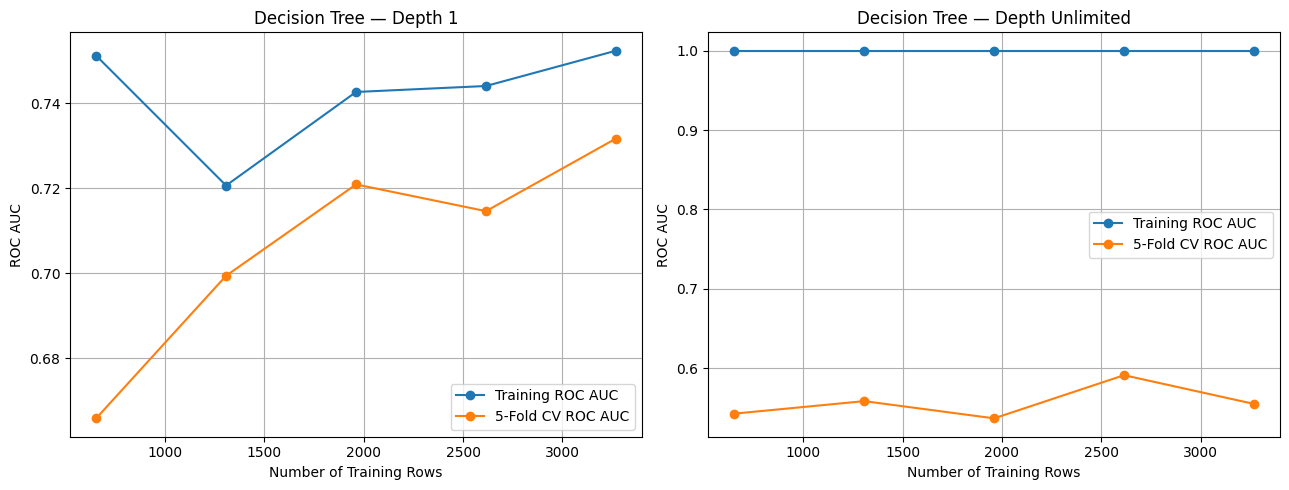

,Depth,Training Rows,Training ROC AUC,CV ROC AUC
0,1,653,0.7512,0.6659
1,1,1307,0.7206,0.6994
2,1,1961,0.7426,0.7209
3,1,2615,0.7440,0.7146
4,1,3269,0.7523,0.7317
5,None,653,1.0000,0.5427
6,None,1307,1.0000,0.5585
7,None,1961,1.0000,0.5368
8,None,2615,1.0000,0.5912
9,None,3269,1.0000,0.5550


In [10]:
train_sizes_fraction = np.linspace(0.2, 1.0, 5)
depth_options = [1, None]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

learning_results = []

for ax, depth in zip(axes, depth_options):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)

    sizes, train_scores, cv_scores = learning_curve(
        tree,
        X_train,
        y_train,
        train_sizes=train_sizes_fraction,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        shuffle=True,
        random_state=SEED
    )

    train_mean = train_scores.mean(axis=1)
    cv_mean = cv_scores.mean(axis=1)

    ax.plot(sizes, train_mean, marker="o", label="Training ROC AUC")
    ax.plot(sizes, cv_mean, marker="o", label="5-Fold CV ROC AUC")
    ax.set_xlabel("Number of Training Rows")
    ax.set_ylabel("ROC AUC")
    ax.set_title(f"Decision Tree — Depth {depth if depth else 'Unlimited'}")
    ax.legend()
    ax.grid(True)

    for i in range(len(sizes)):
        learning_results.append({
            "Depth": str(depth),
            "Training Rows": sizes[i],
            "Training ROC AUC": train_mean[i],
            "CV ROC AUC": cv_mean[i]
        })

plt.tight_layout()
plt.show()

display(pd.DataFrame(learning_results).round(4))

# Task 3

In [11]:
rng = np.random.default_rng(SEED)
n_bootstraps = 40
depth_options = [1, 3, None]

bootstrap_results = []
bootstrap_predictions = {}

for depth in depth_options:
    predictions = []

    for i in range(n_bootstraps):
       
        sample_indices = rng.integers(0, len(X_train), size=len(X_train))

        X_boot = X_train.iloc[sample_indices]
        y_boot = y_train.iloc[sample_indices]

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED + i
        )
        tree.fit(X_boot, y_boot)

        
        class_1_index = list(tree.classes_).index(1)
        probabilities = tree.predict_proba(X_test)[:, class_1_index]

        predictions.append(probabilities)

    predictions = np.array(predictions)
    bootstrap_predictions[str(depth)] = predictions

    # Variance across trees for each test patient, then average
    mean_prediction_variance = np.var(predictions, axis=0).mean()

    # Average ROC AUC of individual trees
    individual_auc = [
        roc_auc_score(y_test, predictions[i])
        for i in range(n_bootstraps)
    ]

    # ROC AUC after averaging predictions from all trees
    averaged_predictions = predictions.mean(axis=0)
    averaged_auc = roc_auc_score(y_test, averaged_predictions)

    bootstrap_results.append({
        "Depth": str(depth),
        "Mean Prediction Variance": mean_prediction_variance,
        "Mean Individual Tree ROC AUC": np.mean(individual_auc),
        "ROC AUC of Averaged Predictions": averaged_auc
    })

bootstrap_df = pd.DataFrame(bootstrap_results)
display(bootstrap_df.round(4))

,Depth,Mean Prediction Variance,Mean Individual Tree ROC AUC,ROC AUC of Averaged Predictions
0,1,0.0007,0.7623,0.8132
1,3,0.0017,0.7963,0.8339
2,None,0.0422,0.5526,0.7682


# Questions
## a)From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone. 
       Depth 1 underfits (high bias). At depth 1 the training AUC is only 0.7523 and the CV AUC is 0.7317, so the model is poor on both and the gap is small (0.02). It is too simple to capture the pattern. Depths 5 and above overfit (high variance). At depth 10 the training AUC is 0.9875 but the CV AUC falls to 0.6444, and with no depth limit the training AUC is a perfect 1.0000 while the CV AUC is only 0.5550, barely better than guessing. The best zone is depths 2–4, where CV AUC peaks at about 0.82. I would choose depth 4: it has the highest CV AUC (0.8180), with a training AUC of 0.8658 and a modest gap of about 0.05. Depth 2 or 3 would be almost as good (CV 0.8168 and 0.8161) and slightly simpler.
## b)From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one? 
    High bias occurs when training and CV scores are both relatively low and close together, as with the shallow tree. High variance occurs when training performance is much higher than CV performance, as with the unlimited-depth tree. Adding more training rows may reduce high variance, but it will not necessarily fix high bias; a more complex model may be needed. In my learning curves, more rows did not eliminate the large gap for the unlimited-depth tree.
## c)From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4). 
    Prediction variance increases with depth: 0.0007 at depth 1, 0.0017 at depth 3, and 0.0422 at unlimited depth. Averaging predictions improves ROC AUC for all three depths. For depth 3, AUC improves from 0.7963 for individual trees on average to 0.8339 for averaged predictions. This is related to Random Forests, which combine predictions from multiple trees to reduce variance and improve generalization.
## d)In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit? 
    The bias–variance trade-off means balancing a model that is too simple to learn important patterns against one that is too complex and learns noise from the training data.
    - Depth 1: Higher bias, low variance; likely underfits.
    - Depth 3: A more balanced model, with better performance in the bootstrap experiment.
    - Depth None: Low training error but high variance and severe overfitting.
    The goal is not to maximize training performance, but to choose a model that performs well on unseen data.

# Part 3: ROC, AUC, Precision-Recall and Thresholds

# Task 1

,Model,ROC AUC,PR AUC (Average Precision)
0,Logistic Regression,0.8393,0.2696
1,Decision Tree (depth=3),0.7956,0.1621
2,Random Forest,0.8215,0.2183


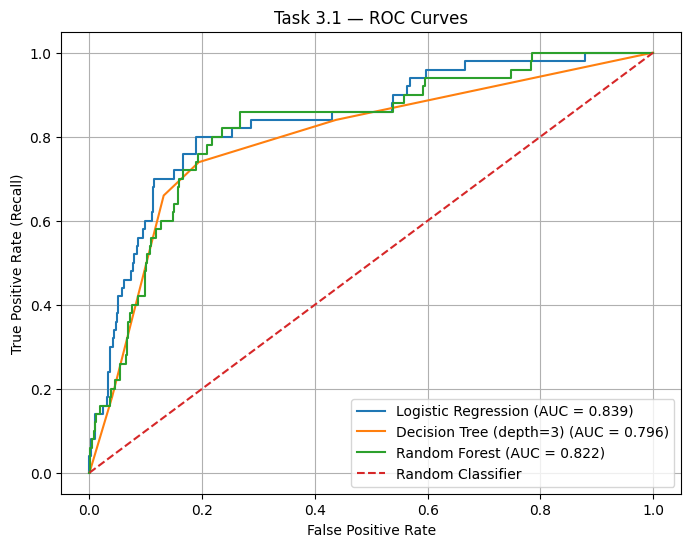

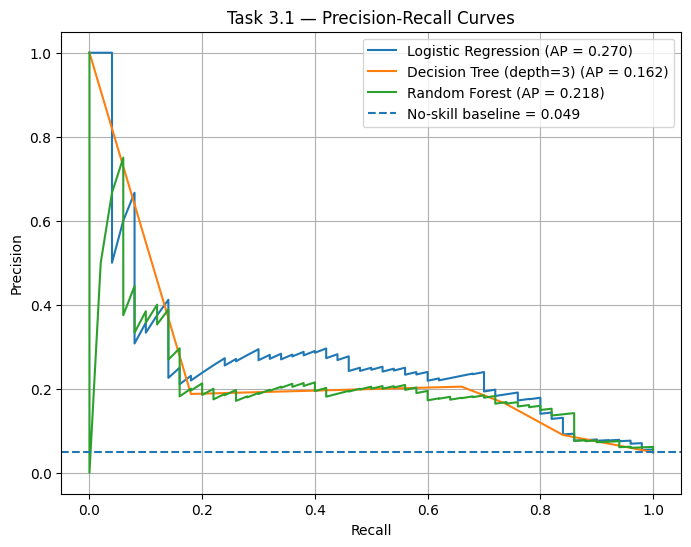

Test-set stroke prevalence: 0.0489


In [12]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=SEED
    ),
    "Decision Tree (depth=3)": DecisionTreeClassifier(
        max_depth=3, random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED,
        n_jobs=-1
    )
}

# Logistic Regression uses scaled data; tree models use original data.
X_train_models = {
    "Logistic Regression": X_train_scaled,
    "Decision Tree (depth=3)": X_train,
    "Random Forest": X_train
}

X_test_models = {
    "Logistic Regression": X_test_scaled,
    "Decision Tree (depth=3)": X_test,
    "Random Forest": X_test
}

model_probabilities = {}
model_results = []

for name, model in models.items():
    model.fit(X_train_models[name], y_train)

    probabilities = model.predict_proba(X_test_models[name])[:, 1]
    model_probabilities[name] = probabilities

    model_results.append({
        "Model": name,
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "PR AUC (Average Precision)": average_precision_score(
            y_test, probabilities
        )
    })

display(pd.DataFrame(model_results).round(4))

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Task 3.1 — ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

stroke_rate = y_test.mean()

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    plt.plot(recall, precision, label=f"{name} (AP = {ap:.3f})")

plt.axhline(
    y=stroke_rate,
    linestyle="--",
    label=f"No-skill baseline = {stroke_rate:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Task 3.1 — Precision-Recall Curves")
plt.legend()
plt.grid(True)
plt.show()

print("Test-set stroke prevalence:", round(stroke_rate, 4))


**Interpretation: ROC and Precision-Recall curves**

On the ROC chart, Logistic Regression has the highest AUC (0.8393), then Random Forest (0.8215) and the depth-3 tree (0.7956). All three are well above the diagonal (0.5), so all three rank stroke patients above healthy patients much better than chance, and the gaps between them are small.

On the PR chart the models separate more clearly. Average precision is 0.2696 for Logistic Regression, 0.2183 for Random Forest and 0.1621 for the tree, against a no-skill line of 0.0489 (the stroke rate). Logistic Regression is about 5.5 times better than no-skill, but its precision still drops quickly as recall rises, which means catching more strokes brings many false alarms. Logistic Regression is the best model on both charts, so I use it for the threshold in Task 2.

# Task 2

In [13]:
lr_threshold_model = LogisticRegression(
    max_iter=1000, random_state=SEED
)

oof_probabilities = cross_val_predict(
    lr_threshold_model,
    X_train_scaled,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

threshold_candidates = np.sort(np.unique(oof_probabilities))
threshold_results = []

for threshold in threshold_candidates:
    oof_pred = (oof_probabilities >= threshold).astype(int)
    recall = recall_score(y_train, oof_pred, zero_division=0)
    precision = precision_score(y_train, oof_pred, zero_division=0)

    if recall >= 0.80:
        threshold_results.append({
            "Threshold": threshold,
            "Recall": recall,
            "Precision": precision
        })

if threshold_results:
    threshold_df = pd.DataFrame(threshold_results)
   
    chosen_row = threshold_df.loc[threshold_df["Threshold"].idxmax()]
    chosen_threshold = chosen_row["Threshold"]

    print("Chosen threshold:", round(chosen_threshold, 4))
    print("OOF recall:", round(chosen_row["Recall"], 4))
    print("OOF precision:", round(chosen_row["Precision"], 4))
else:
    chosen_threshold = 0.5
    print("No threshold achieved recall >= 0.80; using 0.5 as fallback.")



lr_final = LogisticRegression(max_iter=1000, random_state=SEED)
lr_final.fit(X_train_scaled, y_train)

test_probabilities = lr_final.predict_proba(X_test_scaled)[:, 1]
threshold_pred = (test_probabilities >= chosen_threshold).astype(int)

threshold_cm = confusion_matrix(y_test, threshold_pred)

threshold_recall = recall_score(
    y_test, threshold_pred, zero_division=0
)
threshold_precision = precision_score(
    y_test, threshold_pred, zero_division=0
)

tn, fp, fn, tp = threshold_cm.ravel()

print("Chosen threshold:", round(chosen_threshold, 4))
print("Test Recall:", round(threshold_recall, 4))
print("Test Precision:", round(threshold_precision, 4))
print("Confusion Matrix:\n", threshold_cm)
print("Patients flagged as stroke:", int(tp + fp))
print("False alarms:", int(fp))
print("Missed stroke cases:", int(fn))

Chosen threshold: 0.0507
OOF recall: 0.804
OOF precision: 0.1357
Chosen threshold: 0.0507
Test Recall: 0.82
Test Precision: 0.1344
Confusion Matrix:
 [[708 264]
 [  9  41]]
Patients flagged as stroke: 305
False alarms: 264
Missed stroke cases: 9


# Questions
## a) In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is much higher than 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?
    AUC measures ranking, not labels. A ROC AUC of 0.8393 means that if I pick a random stroke patient and a random healthy patient, the model gives the stroke patient the higher probability about 84% of the time. It says nothing about where the cut-off is. Recall depends on the cut-off. With only about 5% strokes, the model's probabilities are low for almost everyone, so at the default 0.5 only 1 of 50 strokes crosses the line (recall 0.02). The ranking is still good: when I lowered the cut-off to 0.0507, 41 of 50 strokes were caught (recall 0.82). The model was not bad. The 0.5 threshold was a poor fit for a rare class.
## b) Which metric curve is more informative for this data - ROC or Precision-Recall - and why? Use the no-skill line in your answer.
    The Precision-Recall curve is more informative here. On the ROC chart the no-skill line is the diagonal and all three models look good (AUC 0.7956 to 0.8393), because the false positive rate divides false alarms by the 972 healthy patients, which hides how many false alarms there are. At my threshold, 264 false alarms is only 27% on the ROC axis, yet the precision is just 13.4%. The PR chart shows this directly. Its no-skill line is the stroke rate, 0.0489, and the best model (Logistic Regression, AP 0.2696) is only about 5.5 times above it, with precision falling fast as recall rises. The PR chart shows the real difficulty of the problem and separates the models more clearly (AP 0.2696 vs 0.2183 vs 0.1621).
## c) At your chosen threshold, what is the price the hospital pays for the higher recall? Is it acceptable? Argue both sides in 3-4 lines.
    The price is false alarms. At threshold 0.0507 the model flags 305 of 1,022 patients (about 30%). Only 41 of them had a stroke (precision 0.1344), and 264 healthy patients are flagged, about 27% of all healthy patients. Roughly 6 of every 7 flagged patients are healthy.
    For acceptable: at the default threshold the model catches 1 stroke out of 50, while this one catches 41 and misses only 9. A missed stroke can cause death or permanent disability, and a follow-up check such as a blood pressure test or an ECG is cheap by comparison.
    Against: flagging about 3 in 10 patients creates a heavy workload, cost and anxiety for patients who are healthy, and 9 strokes are still missed. With only 50 strokes in the test set, a recall of 0.82 is also uncertain by several points. My view: acceptable as a first-stage screening filter if follow-up is low-cost, but not as a diagnosis.

# Part 4 : Undersampling, Oversampling and SMOTE

# Task 1

In [14]:
# Task 1

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

resampling_methods = {
    "No Resampling": None,
    "Class Weights": "balanced",
    "Random Undersampling": RandomUnderSampler(random_state=SEED),
    "Random Oversampling": RandomOverSampler(random_state=SEED),
    "SMOTE": SMOTE(random_state=SEED)
}

models_part4 = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED,
        n_jobs=-1
    )
}

X_train_part4 = {
    "Logistic Regression": X_train_scaled,
    "Random Forest": X_train
}

X_test_part4 = {
    "Logistic Regression": X_test_scaled,
    "Random Forest": X_test
}

results_part4 = []

for model_name, model in models_part4.items():

    for method_name, sampler in resampling_methods.items():

        Xtr = X_train_part4[model_name]
        Xte = X_test_part4[model_name]
        ytr = y_train.copy()

        if sampler == "balanced":
            model.set_params(class_weight="balanced")

        else:
            model.set_params(class_weight=None)

            if sampler is not None:
                Xtr, ytr = sampler.fit_resample(Xtr, ytr)

        model.fit(Xtr, ytr)

        y_pred = model.predict(Xte)
        y_prob = model.predict_proba(Xte)[:, 1]

        results_part4.append({
            "Model": model_name,
            "Method": method_name,
            "Training Rows": len(ytr),
            "Stroke Cases": int(ytr.sum()),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, y_prob),
            "PR AUC": average_precision_score(y_test, y_prob)
        })

results_part4_df = pd.DataFrame(results_part4)

display(results_part4_df.round(4))

,Model,Method,Training Rows,Stroke Cases,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression,No Resampling,4087,199,1.0000,0.02,0.0392,0.8393,0.2696
1,Logistic Regression,Class Weights,4087,199,0.1347,0.80,0.2305,0.8396,0.2596
2,Logistic Regression,Random Undersampling,398,199,0.1246,0.82,0.2164,0.8350,0.2333
3,Logistic Regression,Random Oversampling,7776,3888,0.1333,0.80,0.2286,0.8385,0.2591
4,Logistic Regression,SMOTE,7776,3888,0.1347,0.80,0.2305,0.8407,0.2957
5,Random Forest,No Resampling,4087,199,0.0000,0.00,0.0000,0.8215,0.2183
6,Random Forest,Class Weights,4087,199,0.1667,0.20,0.1818,0.8061,0.2045
7,Random Forest,Random Undersampling,398,199,0.1032,0.84,0.1838,0.8132,0.1972
8,Random Forest,Random Oversampling,7776,3888,0.1412,0.24,0.1778,0.8023,0.1837
9,Random Forest,SMOTE,7776,3888,0.6667,0.04,0.0755,0.8046,0.2424


# Task 2

In [15]:
X_imputed = X.copy()

X_imputed = pd.DataFrame(
    imputer.transform(X_imputed),
    columns=X.columns,
    index=X.index
)

smote_wrong = SMOTE(random_state=SEED)

X_wrong, y_wrong = smote_wrong.fit_resample(X_imputed, y)

X_train_wrong, X_test_wrong, y_train_wrong, y_test_wrong = train_test_split(
    X_wrong,
    y_wrong,
    test_size=0.20,
    random_state=SEED,
    stratify=y_wrong
)

rf_wrong = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

rf_wrong.fit(X_train_wrong, y_train_wrong)

wrong_pred = rf_wrong.predict(X_test_wrong)
wrong_prob = rf_wrong.predict_proba(X_test_wrong)[:, 1]

wrong_results = {
    "Precision": precision_score(y_test_wrong, wrong_pred, zero_division=0),
    "Recall": recall_score(y_test_wrong, wrong_pred, zero_division=0),
    "F1": f1_score(y_test_wrong, wrong_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test_wrong, wrong_prob),
    "PR AUC": average_precision_score(y_test_wrong, wrong_prob)
}

display(pd.DataFrame([wrong_results]).round(4))

,Precision,Recall,F1,ROC AUC,PR AUC
0,0.9978,0.9506,0.9737,0.9952,0.996


In [16]:
# Task 2 — Correct approach: SMOTE after train-test split

smote_correct = SMOTE(random_state=SEED)

X_train_correct, y_train_correct = smote_correct.fit_resample(
    X_train,
    y_train
)

rf_correct = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

rf_correct.fit(X_train_correct, y_train_correct)

correct_pred = rf_correct.predict(X_test)
correct_prob = rf_correct.predict_proba(X_test)[:, 1]

correct_results = {
    "Precision": precision_score(y_test, correct_pred, zero_division=0),
    "Recall": recall_score(y_test, correct_pred, zero_division=0),
    "F1": f1_score(y_test, correct_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, correct_prob),
    "PR AUC": average_precision_score(y_test, correct_prob)
}

display(pd.DataFrame([correct_results]).round(4))

,Precision,Recall,F1,ROC AUC,PR AUC
0,0.6667,0.04,0.0755,0.8046,0.2424


In [17]:
# Task 4.2 — Wrong order vs correct order, side by side
comparison_42 = pd.DataFrame(
    [wrong_results, correct_results],
    index=["Wrong order (SMOTE before split)",
           "Correct order (SMOTE after split)"]
)

# Show what each model was actually tested on
comparison_42["Test Rows"] = [len(y_test_wrong), len(y_test)]
comparison_42["Strokes in Test"] = [int(y_test_wrong.sum()), int(y_test.sum())]

display(comparison_42.round(4))

,Precision,Recall,F1,ROC AUC,PR AUC,Test Rows,Strokes in Test
Wrong order (SMOTE before split),0.9978,0.9506,0.9737,0.9952,0.9960,1944,972
Correct order (SMOTE after split),0.6667,0.0400,0.0755,0.8046,0.2424,1022,50


**Interpretation: Wrong order vs correct order**

The wrong-order Random Forest scores ROC AUC = 0.9952 and PR AUC = 0.9960. The correct-order model scores ROC AUC = 0.8046 and PR AUC = 0.2424 on the same kind of model. Recall is 0.9506 versus only 0.04, and F1 is 0.9737 versus 0.0755.

The gap is not a real improvement. In the wrong order, SMOTE ran on all 5,109 patients first, so the test set was no longer real patients. It was about 972 strokes, many of them synthetic, out of 1,944 rows, with a 50/50 class balance. The correct test set is 1,022 real patients with only 50 strokes (4.9%). The two rows are not even measured on the same kind of data.

# Questions
## a)For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.
    Resampling significantly improved Recall. Without resampling, Recall was only 0.02, meaning the model detected just 2% of stroke cases. After applying class weights, random undersampling, random oversampling and SMOTE, Recall increased to 0.80–0.82.
    However, Precision decreased from 1.0000 to approximately 0.1246–0.1347. This means the model detected more stroke patients but also produced more false alarms.
    ROC AUC remained almost unchanged, ranging from 0.8350 to 0.8407, compared with 0.8393 without resampling. This indicates that the model's ability to distinguish between the two classes remained similar. Resampling mainly changed the model's learning balance and classification behaviour rather than greatly improving its overall ranking ability.
## b)Did Random Forest react to the methods in the same way as Logistic Regression? Describe one clear difference and give one possible reason.
        No, Random Forest did not react to the resampling methods in the same way as Logistic Regression.
    Without resampling, Random Forest had a Recall of 0.00, meaning it failed to detect any stroke cases. Random undersampling increased its Recall to 0.84, while class weights increased it to 0.20. However, SMOTE produced a very different result, with Precision of 0.6667 but Recall of only 0.04.   
    In comparison, Logistic Regression achieved a Recall of 0.80 with SMOTE. One possible reason is that Logistic Regression learns a linear decision boundary, while Random Forest combines multiple decision trees and learns more complex patterns. Therefore, the two models respond differently to changes in the training data distribution.
## c) Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where. 
    The wrong-order SMOTE approach produced almost perfect results, with ROC AUC = 0.9952 and PR AUC = 0.9960. In comparison, the correct approach achieved ROC AUC = 0.8046 and PR AUC = 0.2424.
       The wrong results are so good because SMOTE was run on all the data before splitting. SMOTE builds each synthetic stroke by interpolating between a real stroke and one of its nearest stroke neighbours. After the random split, those synthetic points and their parent patients land on both sides. So a stroke patient in the test set often has a near-copy sitting in the training set, and the forest only has to recognise points it has effectively already seen. The test set also contains synthetic patients rather than real ones. This is why recall jumps to 0.9506 while the honest result is 0.04. The numbers cannot be trusted because they measure memorisation of near-duplicates, not performance on new patients.  
    As a result, the model was evaluated on data that was no longer completely independent of its training data. This makes the performance look unrealistically high. The correct approach applies SMOTE only to the training set and keeps the original test set untouched, giving a more reliable evaluation.
## d) If you had to pick one rebalancing approach for this hospital, which would you pick and why? Consider simplicity and the cost of each choice. 
    I would choose Class Weights (class_weight='balanced') with Logistic Regression. It achieved a Recall of 0.80 and Precision of 0.1347, meaning it detected 80% of stroke cases while accepting some false alarms.
    This approach is simple because it does not require removing majority-class samples or generating synthetic data. It also preserves the original training dataset. Although SMOTE achieved a slightly higher PR AUC of 0.2957, class weights provide a simpler alternative with almost the same Recall and Precision.
    For a hospital screening system, missing a patient who may have a stroke can be more costly than conducting additional medical checks on patients who are not at risk. Therefore, I would prefer class weights as a practical starting approach, while monitoring false alarms and validating the model further before real-world use.

# Part 5 : Noisy Data

# Task 1

In [18]:
def add_label_noise(y, noise_fraction, random_state):
    y_noisy = y.to_numpy().copy()

    rng = np.random.default_rng(random_state)

    n_flip = int(len(y_noisy) * noise_fraction)

    flip_indices = rng.choice(
        len(y_noisy),
        size=n_flip,
        replace=False
    )

    y_noisy[flip_indices] = 1 - y_noisy[flip_indices]

    return pd.Series(y_noisy, index=y.index)

,Noise Fraction,Logistic Regression,Decision Tree (depth=3),Decision Tree (unlimited),Random Forest
0,0.00,0.8393,0.7956,0.5722,0.8215
1,0.05,0.8239,0.8014,0.5550,0.7896
2,0.10,0.8050,0.7830,0.5265,0.7425
3,0.20,0.7745,0.7263,0.5060,0.6699


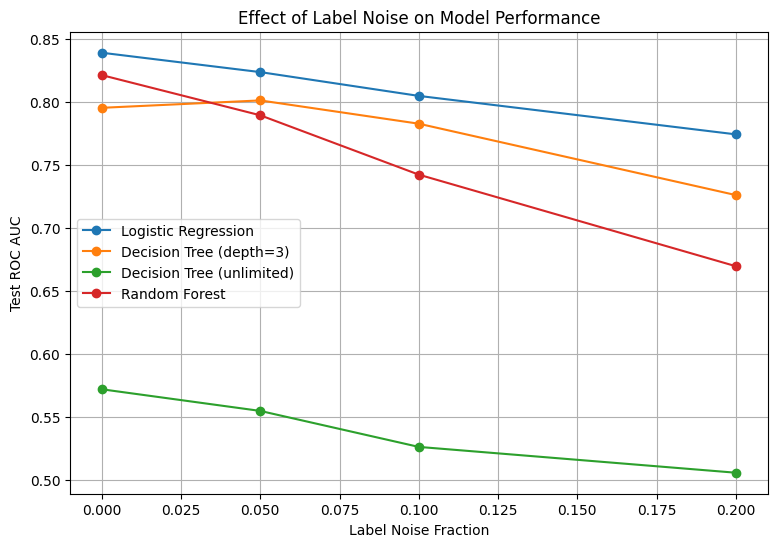

In [19]:
noise_fractions = [0, 0.05, 0.10, 0.20]

label_noise_results = []

for noise_fraction in noise_fractions:

    repeats = 1 if noise_fraction == 0 else 5
    auc_scores = {
        "Logistic Regression": [],
        "Decision Tree (depth=3)": [],
        "Decision Tree (unlimited)": [],
        "Random Forest": []
    }

    for repeat in range(repeats):

        y_train_noisy = add_label_noise(
            y_train,
            noise_fraction,
            SEED + repeat
        )

        models_noise = {
            "Logistic Regression": LogisticRegression(
                max_iter=1000,
                random_state=SEED
            ),
            "Decision Tree (depth=3)": DecisionTreeClassifier(
                max_depth=3,
                random_state=SEED
            ),
            "Decision Tree (unlimited)": DecisionTreeClassifier(
                random_state=SEED
            ),
            "Random Forest": RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=5,
                random_state=SEED,
                n_jobs=-1
            )
        }

        X_train_noise = {
            "Logistic Regression": X_train_scaled,
            "Decision Tree (depth=3)": X_train,
            "Decision Tree (unlimited)": X_train,
            "Random Forest": X_train
        }

        X_test_noise = {
            "Logistic Regression": X_test_scaled,
            "Decision Tree (depth=3)": X_test,
            "Decision Tree (unlimited)": X_test,
            "Random Forest": X_test
        }

        for model_name, model in models_noise.items():

            model.fit(
                X_train_noise[model_name],
                y_train_noisy
            )

            y_prob = model.predict_proba(
                X_test_noise[model_name]
            )[:, 1]

            auc_scores[model_name].append(
                roc_auc_score(y_test, y_prob)
            )

    label_noise_results.append({
        "Noise Fraction": noise_fraction,
        "Logistic Regression": np.mean(
            auc_scores["Logistic Regression"]
        ),
        "Decision Tree (depth=3)": np.mean(
            auc_scores["Decision Tree (depth=3)"]
        ),
        "Decision Tree (unlimited)": np.mean(
            auc_scores["Decision Tree (unlimited)"]
        ),
        "Random Forest": np.mean(
            auc_scores["Random Forest"]
        )
    })

label_noise_df = pd.DataFrame(label_noise_results)

display(label_noise_df.round(4))

# Line plot

plt.figure(figsize=(9, 6))

for model_name in label_noise_df.columns[1:]:
    plt.plot(
        label_noise_df["Noise Fraction"],
        label_noise_df[model_name],
        marker="o",
        label=model_name
    )

plt.xlabel("Label Noise Fraction")
plt.ylabel("Test ROC AUC")
plt.title("Effect of Label Noise on Model Performance")
plt.legend()
plt.grid(True)
plt.show()

**Interpretation : Effect of Label Noise**

The results show that increasing label noise reduces the test ROC AUC of all four models.

Logistic Regression decreased from **0.8393** with no noise to **0.7745** at 20% noise. Decision Tree (depth=3) decreased from **0.7956** to **0.7263**, while the unlimited Decision Tree decreased from **0.5722** to **0.5060**.

Random Forest showed the largest performance drop, from **0.8215** to **0.6699**. This suggests that it was more affected by incorrect training labels in this experiment.

Overall, Logistic Regression was the most stable model, with the smallest absolute decrease in ROC AUC (0.0648). The unlimited Decision Tree performed poorly even without added noise, which is consistent with the high-variance behaviour observed in Part 2. As noise increases, models learn from increasingly incorrect target labels, making their predictions less reliable.

# Task 2

,Noise Level,Logistic Regression,Decision Tree (depth=3),Decision Tree (unlimited),Random Forest
0,0.0,0.8393,0.7956,0.5722,0.8215
1,0.5,0.8337,0.7995,0.5751,0.8082
2,1.0,0.8098,0.7610,0.5271,0.7782
3,2.0,0.7690,0.6942,0.5283,0.7352


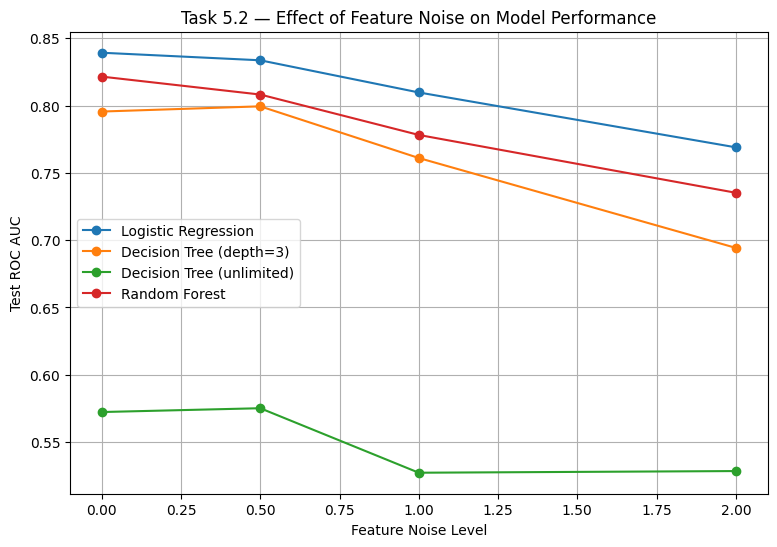

In [20]:
noise_levels = [0, 0.5, 1, 2]

feature_columns = ["age", "avg_glucose_level", "bmi"]

feature_std = X_train[feature_columns].std()

feature_noise_results = []

for noise_level in noise_levels:

    auc_scores = {
        "Logistic Regression": [],
        "Decision Tree (depth=3)": [],
        "Decision Tree (unlimited)": [],
        "Random Forest": []
    }

    for repeat in range(5):

        rng = np.random.default_rng(SEED + repeat)

        X_train_noisy = X_train.copy()

        for col in feature_columns:
            noise = (
                rng.normal(0, 1, len(X_train_noisy))
                * feature_std[col]
                * noise_level
            )

            X_train_noisy[col] = X_train_noisy[col] + noise

        # Fit scaler on noisy training data only
        scaler_noise = StandardScaler()

        X_train_noisy_scaled = pd.DataFrame(
            scaler_noise.fit_transform(X_train_noisy),
            columns=X_train_noisy.columns,
            index=X_train_noisy.index
        )

        X_test_noise_scaled = pd.DataFrame(
            scaler_noise.transform(X_test),
            columns=X_test.columns,
            index=X_test.index
        )

        models_feature_noise = {
            "Logistic Regression": LogisticRegression(
                max_iter=1000,
                random_state=SEED
            ),
            "Decision Tree (depth=3)": DecisionTreeClassifier(
                max_depth=3,
                random_state=SEED
            ),
            "Decision Tree (unlimited)": DecisionTreeClassifier(
                random_state=SEED
            ),
            "Random Forest": RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=5,
                random_state=SEED,
                n_jobs=-1
            )
        }

        for model_name, model in models_feature_noise.items():

            if model_name == "Logistic Regression":
                Xtr = X_train_noisy_scaled
                Xte = X_test_noise_scaled
            else:
                Xtr = X_train_noisy
                Xte = X_test

            model.fit(Xtr, y_train)

            y_prob = model.predict_proba(Xte)[:, 1]

            auc_scores[model_name].append(
                roc_auc_score(y_test, y_prob)
            )

    feature_noise_results.append({
        "Noise Level": noise_level,
        "Logistic Regression": np.mean(
            auc_scores["Logistic Regression"]
        ),
        "Decision Tree (depth=3)": np.mean(
            auc_scores["Decision Tree (depth=3)"]
        ),
        "Decision Tree (unlimited)": np.mean(
            auc_scores["Decision Tree (unlimited)"]
        ),
        "Random Forest": np.mean(
            auc_scores["Random Forest"]
        )
    })

feature_noise_df = pd.DataFrame(feature_noise_results)

display(feature_noise_df.round(4))

# Line plot

plt.figure(figsize=(9, 6))

for model_name in feature_noise_df.columns[1:]:
    plt.plot(
        feature_noise_df["Noise Level"],
        feature_noise_df[model_name],
        marker="o",
        label=model_name
    )

plt.xlabel("Feature Noise Level")
plt.ylabel("Test ROC AUC")
plt.title("Task 5.2 — Effect of Feature Noise on Model Performance")
plt.legend()
plt.grid(True)
plt.show()

**Interpretation : Effect of Feature Noise**

The results show that increasing feature noise generally reduces the test ROC AUC of all four models.

Logistic Regression decreased from **0.8393** with no noise to **0.7690** at noise level 2. Decision Tree (depth=3) decreased from **0.7956** to **0.6942**, while Random Forest decreased from **0.8215** to **0.7352**.

The unlimited Decision Tree performed poorly even without noise, with an ROC AUC of **0.5722**. Its performance remained relatively low as noise increased, reaching **0.5283** at level 2.
At noise level 0.5 the changes are tiny and go in both directions: Decision Tree (depth=3) goes from 0.7956 to 0.7995 and the unlimited tree from 0.5722 to 0.5751, while Logistic Regression drops from 0.8393 to 0.8337 and Random Forest from 0.8215 to 0.8082. With only 50 stroke cases in the test set, changes this small are within random variation, so I do not read them as noise helping. The real effect shows at levels 1 and 2.

At level 2, Decision Tree (depth=3) is hurt most (drop of 0.1014), followed by Random Forest (0.0863) and Logistic Regression (0.0703). The unlimited tree has the smallest drop (0.0439), but only because it was already close to guessing (0.5722 without noise), so it had little left to lose. Among the models that worked well to begin with, Logistic Regression is the most stable. Its simple linear boundary averages over all rows, so noise in three features shifts it less than it shifts tree splits, which can be pushed to different thresholds by the noisy values.

# Task 3

In [21]:
smote_noise_results = []

for repeat in range(3):

    # Add 10% label noise
    y_train_noisy = add_label_noise(
        y_train,
        0.10,
        SEED + repeat
    )

    # Compare both models with and without SMOTE
    for model_name in ["Logistic Regression", "Random Forest"]:

        if model_name == "Logistic Regression":
            Xtr = X_train_scaled
            Xte = X_test_scaled

            model = LogisticRegression(
                max_iter=1000,
                random_state=SEED
            )

        else:
            Xtr = X_train
            Xte = X_test

            model = RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=5,
                random_state=SEED,
                n_jobs=-1
            )

        for method in ["Without SMOTE", "With SMOTE"]:

            X_resampled = Xtr
            y_resampled = y_train_noisy

            if method == "With SMOTE":
                smote = SMOTE(random_state=SEED + repeat)

                X_resampled, y_resampled = smote.fit_resample(
                    Xtr,
                    y_train_noisy
                )

            model.fit(X_resampled, y_resampled)

            y_prob = model.predict_proba(Xte)[:, 1]

            smote_noise_results.append({
                "Repeat": repeat + 1,
                "Model": model_name,
                "Method": method,
                "ROC AUC": roc_auc_score(y_test, y_prob),
                "PR AUC": average_precision_score(y_test, y_prob)
            })

smote_noise_df = pd.DataFrame(smote_noise_results)

# Average results across the three repeats
smote_noise_summary = (
    smote_noise_df
    .groupby(["Model", "Method"])[["ROC AUC", "PR AUC"]]
    .mean()
    .reset_index()
)

display(smote_noise_summary.round(4))

,Model,Method,ROC AUC,PR AUC
0,Logistic Regression,With SMOTE,0.8063,0.2376
1,Logistic Regression,Without SMOTE,0.8101,0.2244
2,Random Forest,With SMOTE,0.6590,0.1040
3,Random Forest,Without SMOTE,0.7347,0.1412


# Questions
## a) Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level and explain using what you learned in Part 2.
    At 20% label noise, Random Forest is the most damaged: ROC AUC falls from 0.8215 to 0.6699 (drop of 0.1516), more than double any other model. Logistic Regression falls from 0.8393 to 0.7745 (0.0648) and Decision Tree (depth=3) from 0.7956 to 0.7263 (0.0693). Logistic Regression is the most stable of the models that work well.
    Part 2 explains this. Logistic Regression has only about 20 coefficients and the depth-3 tree has very few splits, so they are high-bias, low-variance models that cannot memorise individual wrong labels. Random Forest (200 trees, min_samples_leaf=5) is flexible and can fit small regions of the data, so the wrong labels pull its decision regions in the wrong places. The unlimited tree also fell (0.5722 to 0.5060, drop of 0.0662), but that is not stability. It was already overfitting with a train AUC of 1.0 and a CV AUC of about 0.55 in Part 2, so it was close to guessing before any noise was added and had little left to lose.
## b) Which hurts more here - label noise or feature noise of a comparable level? Give a short reason.
    Label noise hurts more overall, but not for every model. Comparing 20% label noise with feature noise level 2, the average drop across the four models is 0.0880 for label noise and 0.0755 for feature noise. The gap comes mainly from Random Forest (0.1516 vs 0.0863). For Decision Tree (depth=3) feature noise hurts more (0.1014 vs 0.0693), and for Logistic Regression the two are almost equal (0.0648 vs 0.0703). Treat "comparable level" with care, since 20% flips and noise level 2 are not truly the same size.
    The reason is that label noise corrupts the target itself. With only about 5% strokes, flipping 20% of labels turns hundreds of healthy patients into fake strokes, so the model learns from a wrong answer key. Feature noise only blurs three of the 20 columns, so the true label is still correct and the other features still carry signal.
## c) What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.
    For Logistic Regression, SMOTE changed little: ROC AUC went from 0.8101 to 0.8063 and PR AUC rose slightly from 0.2244 to 0.2376. For Random Forest, SMOTE made things clearly worse: ROC AUC fell from 0.7347 to 0.6590 and PR AUC from 0.1412 to 0.1040.
    The reason is how much of the minority class is fake after flipping. With 10% label noise on about 4,087 training rows, roughly 20 real strokes become "healthy" and roughly 390 healthy patients become "stroke". The minority class then has about 570 rows, and around two thirds of them are wrong. SMOTE interpolates between these minority neighbours, so it creates thousands of new "stroke" points, most of them sitting in healthy regions. SMOTE copies and spreads the noise instead of removing it. Random Forest can fit these regions closely and learns them as stroke, while Logistic Regression's simple linear boundary is not able to chase them, which is why it was hurt much less.

# Part 6: Final Decision and Conclusion 

# Task 1

In [22]:
default_pred = (test_probabilities >= 0.5).astype(int)
chosen_pred = (test_probabilities >= chosen_threshold).astype(int)

results = []

for name, predictions in [
    ("Default Threshold (0.5)", default_pred),
    ("Chosen Threshold (0.0507)", chosen_pred)
]:
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions
    ).ravel()

    results.append({
        "Approach": name,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "False Alarms": fp,
        "Missed Strokes": fn
    })

final_results = pd.DataFrame(results)
display(final_results.round(4))

,Approach,Precision,Recall,F1,False Alarms,Missed Strokes
0,Default Threshold (0.5),1.0000,0.02,0.0392,0,49
1,Chosen Threshold (0.0507),0.1344,0.82,0.2310,264,9


The default threshold of 0.5 achieved 100% precision but only 2% recall, missing 49 out of 50 stroke cases. After lowering the threshold to 0.0507, recall increased to 82%, detecting 41 stroke cases. However, precision decreased to 13.44%, resulting in 264 false alarms. This shows the trade-off between detecting more stroke cases and increasing false positives.

# Executive Summary
Logistic Regression with a threshold of 0.0507 was selected as the final approach.

It achieved a test recall of 0.82, detecting 41 out of 50 stroke cases.

Its precision was approximately 0.1344, meaning that only a small proportion of flagged patients actually had a stroke.

The price of higher recall was 264 false alarms and 9 missed stroke cases.

Data leakage was avoided by splitting the dataset before applying SMOTE and other resampling methods.

The threshold was selected using out-of-fold training predictions, without using test labels.

One limitation is that the test set contains only 50 stroke cases, so the evaluation may not represent performance on a larger population.

This model should be treated as a screening-support experiment, not a clinical diagnostic tool.

## a) What was the most surprising result?
    The most surprising result was that Logistic Regression achieved a good ROC-AUC of 0.8393 but detected only 1 out of 50 stroke cases at the default threshold of 0.5. Lowering the threshold to 0.0507 increased recall to 82%, showing how strongly the decision threshold affects minority-class detection.
## b) If you had one more hour, what would you try next?
    I would try hyperparameter tuning and probability calibration to improve the model's performance. I would also test the selected threshold on a larger and more diverse dataset to check whether the results generalize.